# Inventory adjustments — fréquences, motifs et quantités atypiques


# 0. Bibliothèques


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from scipy.stats import binom, fisher_exact
from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.tsaplots import plot_acf
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import cdist
from sklearn.manifold import TSNE
from sklearn.cluster import DBSCAN
from itertools import combinations
from collections import Counter

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'data/data_dictionary.csv').exists()), None)
assert ROOT is not None, 'Lancer le notebook depuis le dépôt.'
plt.rcParams.update({'figure.figsize':(10,4),'axes.grid':True,'grid.alpha':.2})


# 1. Charger les données


In [2]:
raw = pd.read_csv(ROOT / 'data/logistics/inventory_adjustments.csv')
df = pd.read_csv(ROOT / 'data/logistics/cleaned/inventory_adjustments_cleaned.csv')
print('Brut :', raw.shape, '| Nettoyé :', df.shape)


Brut : (140, 11) | Nettoyé : (140, 11)


In [3]:
print("Dimensions :",df.shape)
display(df.head(5))
print("Valeurs manquantes :")
display(df.isna().sum().to_frame("manquants"))
print("Doublons :",df.duplicated().sum())


Dimensions : (140, 11)
Valeurs manquantes :
Doublons : 0


,adjustment_number,facility_code,adjustment_date,item_category,adjustment_quantity,unit,adjustment_reason,approved_by_role,related_receipt_number,related_shipment_number,adjustment_status
0,ADJ-2014-00001,FCL-1007,2014-07-18,medical_consumables,-1.58,case,specialist programme issue,clinical stores manager,NaN,NaN,posted
1,ADJ-2015-00002,FCL-1007,2015-09-10,medical_consumables,-2.70,case,specialist programme issue,specialist programme administrator,NaN,NaN,posted
2,ADJ-2015-00003,FCL-1024,2015-10-30,monitoring_equipment,3.68,kit,late receipt posting,warehouse manager,RCV-2022-00361,NaN,posted
3,ADJ-2016-00004,FCL-1007,2016-01-20,biological_sample,6.52,sealed_lot,late receipt posting,finance controller,NaN,NaN,pending_review
4,ADJ-2016-00005,FCL-1010,2016-02-18,medical_consumables,-2.43,case,procedure stock issue,quality manager,NaN,NaN,posted


,manquants
adjustment_number,0
facility_code,0
adjustment_date,0
item_category,0
adjustment_quantity,0
unit,0
adjustment_reason,0
approved_by_role,1
related_receipt_number,117
related_shipment_number,103


### IQR, Z-score et MAD


# 2. Explorer les ajustements


### Contrôler les ajustements


In [4]:
df["adjustment_date"] = pd.to_datetime(df.adjustment_date, errors="raise")
df["adjustment_quantity"] = pd.to_numeric(df.adjustment_quantity, errors="raise")
assert df.adjustment_date.notna().all() and df.adjustment_quantity.notna().all()
df["magnitude"] = df.adjustment_quantity.abs()
df["signe"] = np.select(
    [df.adjustment_quantity.lt(0), df.adjustment_quantity.gt(0)],
    ["diminution", "augmentation"],
    default="nul",
)
df["groupe_metier"] = df.item_category + " / " + df.unit
df["month"] = df.adjustment_date.dt.to_period("M")
print(
    "Période :", df.adjustment_date.min().date(), "→", df.adjustment_date.max().date()
)


Période : 2014-07-18 → 2025-06-30


In [5]:
display(
    df.groupby(["item_category", "unit"]).agg(
        n=("adjustment_number", "size"),
        negatif=("adjustment_quantity", lambda s: s.lt(0).sum()),
        positif=("adjustment_quantity", lambda s: s.gt(0).sum()),
        min=("adjustment_quantity", "min"),
        mediane=("adjustment_quantity", "median"),
        max=("adjustment_quantity", "max"),
    )
)
display(df.adjustment_status.value_counts(dropna=False))


,,n,negatif,positif,min,mediane,max
item_category,unit,,,,,,
agricultural_product,pallet,19,9,10,-7.91,1.000,7.24
biological_sample,sealed_lot,36,26,10,-7.25,-2.405,7.45
medical_consumables,case,51,41,10,-7.88,-2.070,7.41
monitoring_equipment,kit,20,8,12,-5.10,1.000,7.74
protective_equipment,case,14,5,9,-7.29,2.110,7.87


adjustment_status
posted            90
pending_review    25
approved          25

### Motifs et sens des mouvements


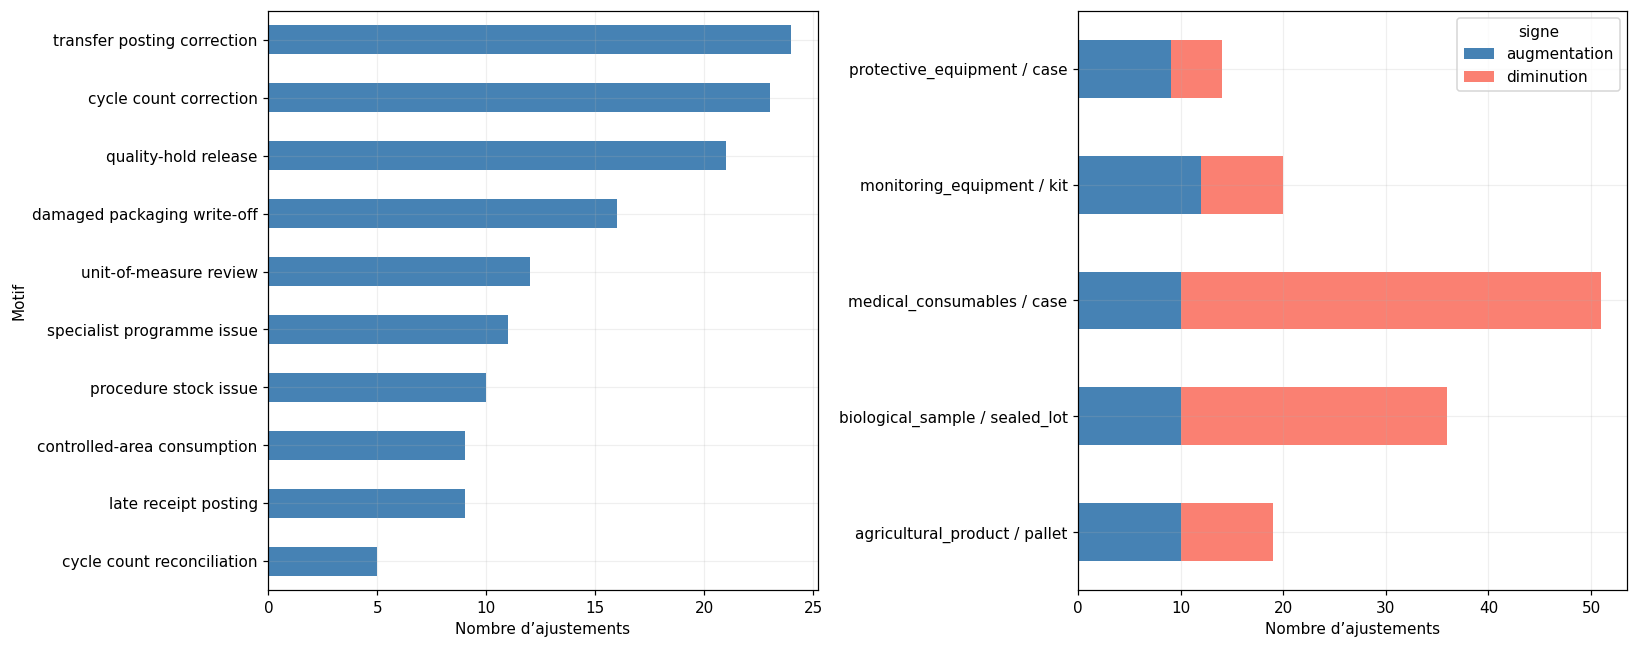

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
df.adjustment_reason.value_counts().sort_values().plot.barh(
    ax=axes[0], color="steelblue"
)
axes[0].set_xlabel("Nombre d’ajustements")
axes[0].set_ylabel("Motif")
pd.crosstab(df.groupe_metier, df.signe).plot.barh(
    stacked=True,
    ax=axes[1],
    color=["steelblue", "salmon", "grey"][: df.signe.nunique()],
)
axes[1].set_xlabel("Nombre d’ajustements")
axes[1].set_ylabel("")
fig.tight_layout()
plt.show()


In [7]:
motifs = pd.crosstab(df.adjustment_reason, df.signe)
display(motifs)
display(pd.crosstab(df.adjustment_reason, df.adjustment_status))
display(
    Markdown(
        "**Lecture :** un motif associé aux deux signes peut décrire des corrections de sens opposés. "
        "Sans convention comptable explicite, on ne transforme pas un signe jugé surprenant en erreur certaine."
    )
)


signe,augmentation,diminution
adjustment_reason,,
controlled-area consumption,0,9
cycle count correction,12,11
cycle count reconciliation,0,5
damaged packaging write-off,9,7
late receipt posting,8,1
procedure stock issue,0,10
quality-hold release,10,11
specialist programme issue,0,11
transfer posting correction,8,16


adjustment_status,approved,pending_review,posted
adjustment_reason,,,
controlled-area consumption,0,0,9
cycle count correction,5,8,10
cycle count reconciliation,0,0,5
damaged packaging write-off,6,4,6
late receipt posting,3,2,4
procedure stock issue,0,0,10
quality-hold release,4,4,13
specialist programme issue,0,0,11
transfer posting correction,4,4,16


**Lecture :** un motif associé aux deux signes peut décrire des corrections de sens opposés. Sans convention comptable explicite, on ne transforme pas un signe jugé surprenant en erreur certaine.

### Quantités par catégorie et unité


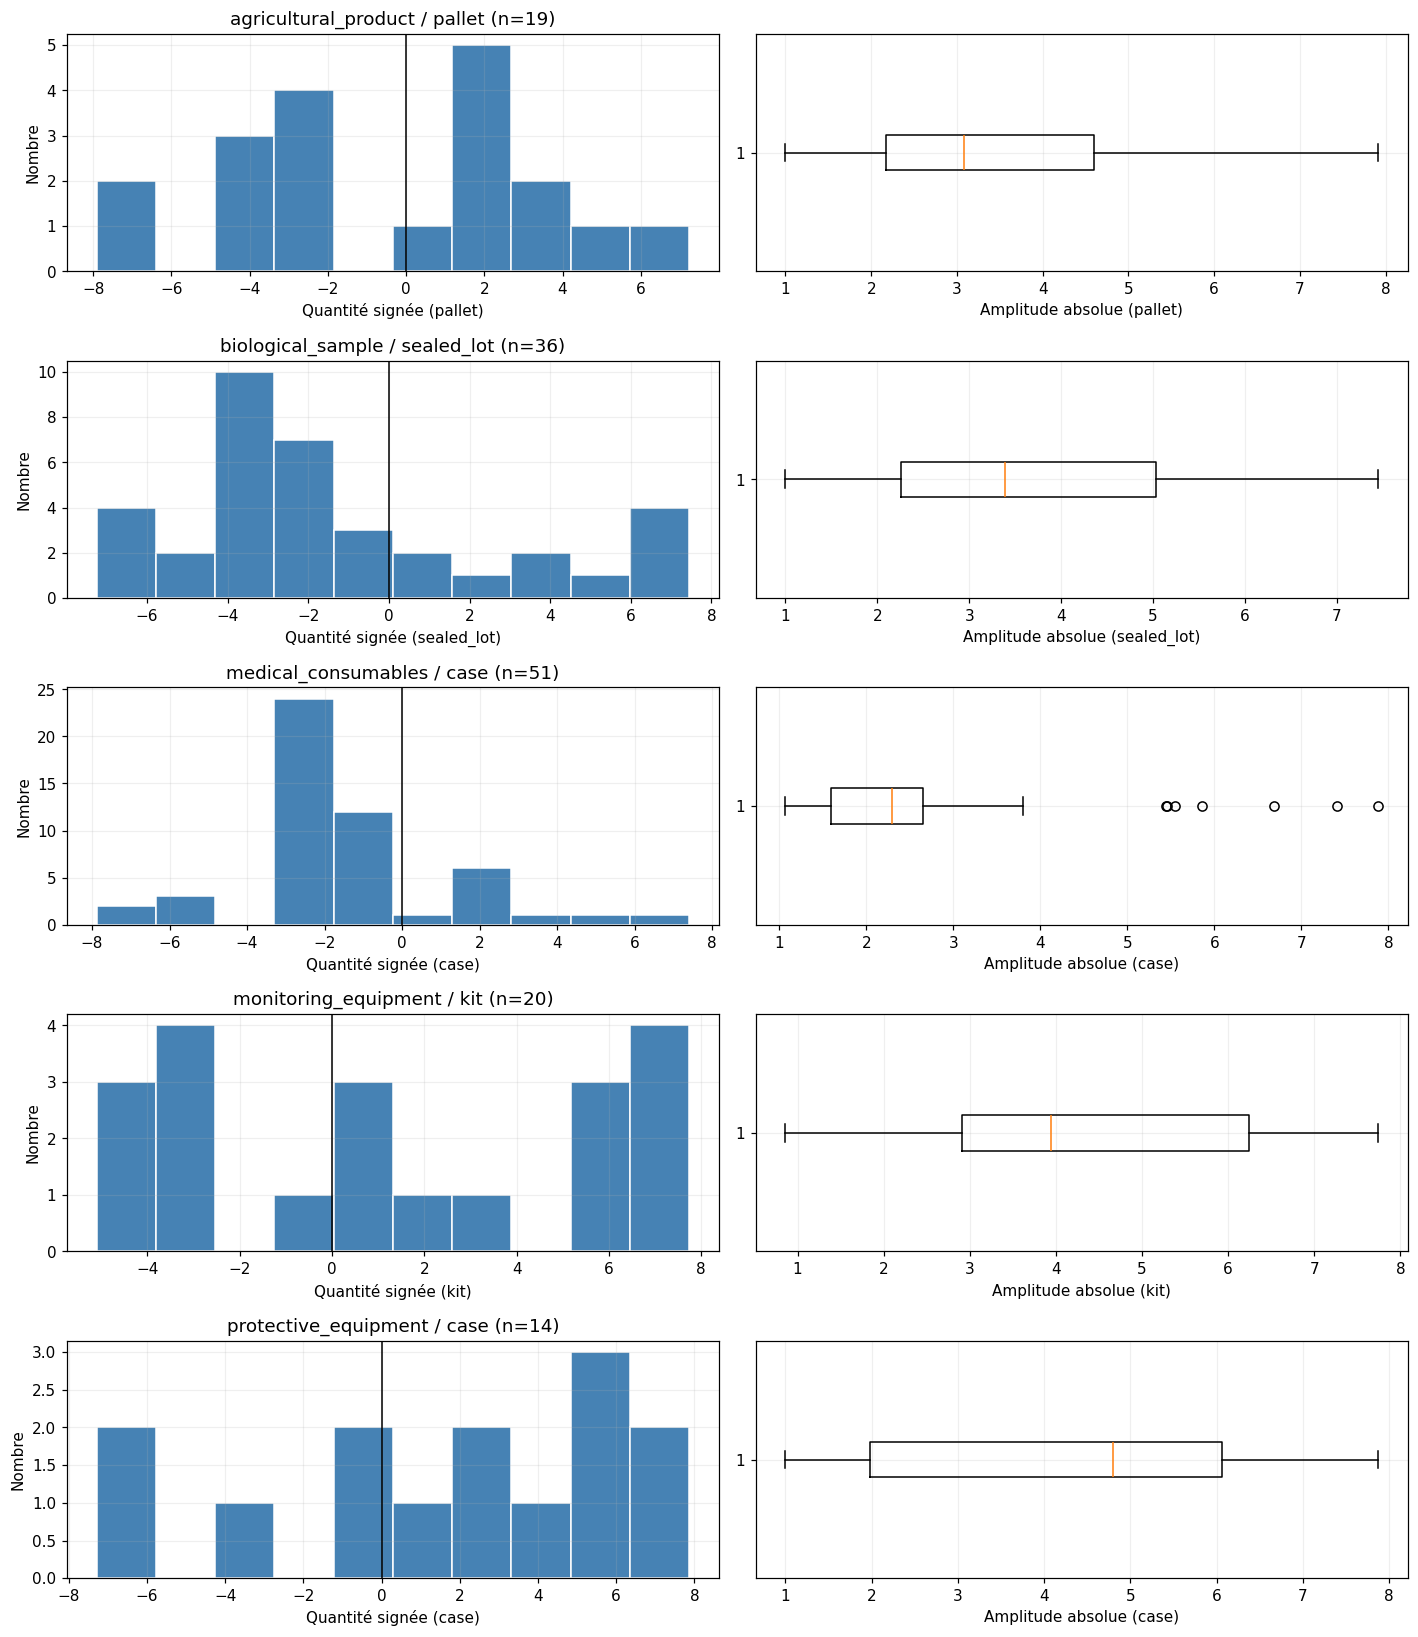

In [8]:
groups = list(df.groupby(["item_category", "unit"]))
fig, axes = plt.subplots(len(groups), 2, figsize=(13, 3 * len(groups)))
for row, ((category, unit), g) in enumerate(groups):
    axes[row, 0].hist(
        g.adjustment_quantity, bins=10, color="steelblue", edgecolor="white"
    )
    axes[row, 0].axvline(0, c="black", lw=1)
    axes[row, 0].set_title(f"{category} / {unit} (n={len(g)})")
    axes[row, 0].set_xlabel(f"Quantité signée ({unit})")
    axes[row, 0].set_ylabel("Nombre")
    axes[row, 1].boxplot(g.magnitude, vert=False)
    axes[row, 1].set_xlabel(f"Amplitude absolue ({unit})")
fig.tight_layout()
plt.show()


In [9]:
balance = df.groupby(["item_category", "unit", "signe"]).agg(
    n=("adjustment_number", "size"),
    total=("adjustment_quantity", "sum"),
    mediane=("adjustment_quantity", "median"),
    amplitude_max=("magnitude", "max"),
)
display(balance)


n   total  mediane  amplitude_max
item_category        unit       signe                                           
agricultural_product pallet     augmentation  10   29.82    2.420           7.24
                                diminution     9  -38.34   -3.530           7.91
biological_sample    sealed_lot augmentation  10   43.40    4.635           7.45
                                diminution    26  -92.51   -3.250           7.25
medical_consumables  case       augmentation  10   28.55    1.925           7.41
                                diminution    41 -107.52   -2.310           7.88
monitoring_equipment kit        augmentation  12   57.06    6.070           7.74
                                diminution     8  -28.07   -3.405           5.10
protective_equipment case       augmentation   9   41.76    5.630           7.87
                                diminution     5  -17.99   -2.900           7.29

### Corrélations et relations entre établissements


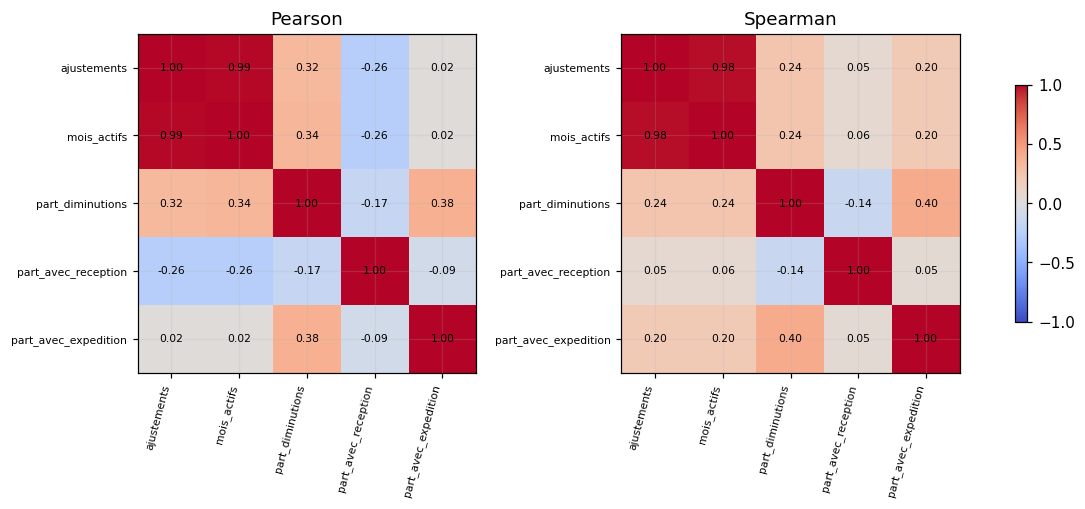

In [10]:
# Comparaison sur des indicateurs sans mélanger les unités des quantités.
facility_stats = df.groupby("facility_code").agg(
    ajustements=("adjustment_number", "size"),
    mois_actifs=("month", "nunique"),
    part_diminutions=("adjustment_quantity", lambda x: x.lt(0).mean()),
    part_avec_reception=("related_receipt_number", lambda x: x.notna().mean()),
    part_avec_expedition=("related_shipment_number", lambda x: x.notna().mean()),
)
variables_stat = facility_stats.columns.tolist()
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, methode in zip(axes, ["pearson", "spearman"]):
    mat = facility_stats.corr(method=methode)
    image = ax.imshow(mat, cmap="coolwarm", vmin=-1, vmax=1)
    ax.set_xticks(range(len(variables_stat)), variables_stat, rotation=75, ha="right", fontsize=7)
    ax.set_yticks(range(len(variables_stat)), variables_stat, fontsize=7)
    for ligne in range(len(variables_stat)):
        for colonne in range(len(variables_stat)):
            ax.text(colonne, ligne, f"{mat.iloc[ligne, colonne]:.2f}",
                    ha="center", va="center", fontsize=7)
    ax.set_title(methode.capitalize())
fig.colorbar(image, ax=axes, shrink=.7)
plt.show()


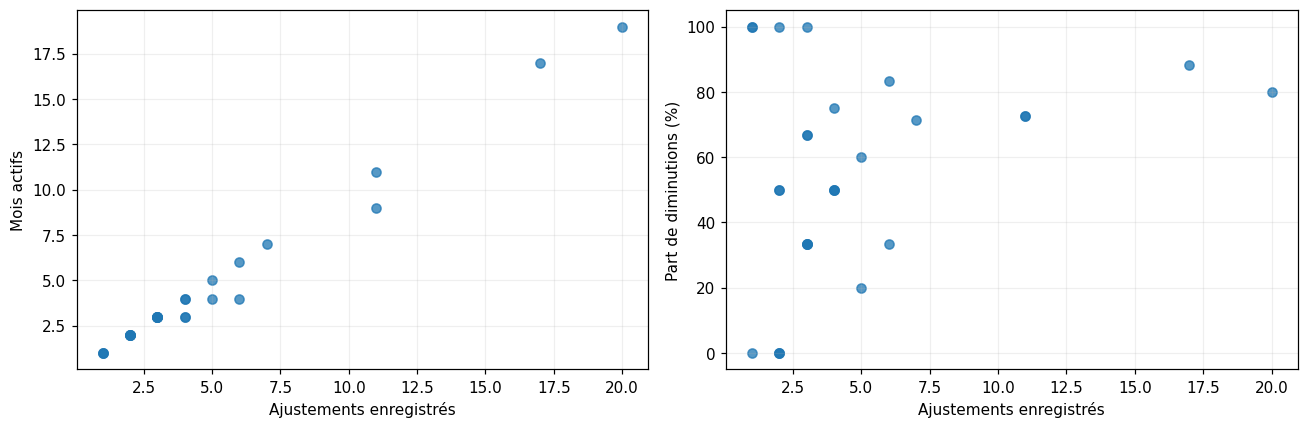

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(facility_stats.ajustements, facility_stats.mois_actifs, alpha=.75)
axes[0].set(xlabel="Ajustements enregistrés", ylabel="Mois actifs")
axes[1].scatter(facility_stats.ajustements, facility_stats.part_diminutions * 100, alpha=.75)
axes[1].set(xlabel="Ajustements enregistrés", ylabel="Part de diminutions (%)")
plt.tight_layout();plt.show()


**Lecture :** on compare ici des nombres et proportions **par établissement**, plutôt que des quantités de produits exprimées dans des unités différentes. Une corrélation entre nombre d’ajustements et mois actifs est attendue en partie par construction. Les proportions restent fragiles pour les établissements qui ont peu d’événements.


# 3. Bloc 2 — Clustering des ajustements


### a. Variables et encodage


In [12]:
profils_stock=df[['adjustment_number','item_category','unit','adjustment_reason',
                  'adjustment_status','adjustment_quantity','magnitude']].copy()
profils_stock['signe_positif']=profils_stock.adjustment_quantity.gt(0).astype(int)
profils_stock['rang_amplitude']=profils_stock.groupby(['item_category','unit']).magnitude.rank(pct=True)
colonnes_cat=['item_category','unit','adjustment_reason','adjustment_status']
categories_stock=pd.get_dummies(profils_stock[colonnes_cat],dtype=int)
X_stock_all=StandardScaler().fit_transform(pd.concat([
    profils_stock[['rang_amplitude','signe_positif']],categories_stock],axis=1))
print('Ajustements :',len(profils_stock),'| variables :',X_stock_all.shape[1])

Ajustements : 140 | variables : 24


### b. K-Means : choix du nombre de clusters


In [13]:
distances_stock=cdist(X_stock_all,X_stock_all,metric='euclidean')
# Les profils standardisés doivent rester finis avant le clustering.
assert np.isfinite(X_stock_all).all()
scores_stock=[]
for k in [2,3,4,5]:
    # Sur certains Mac, NumPy/Accelerate émet des avertissements de matmul
    # malgré des données finies ; on vérifie les centres après le calcul.
    with np.errstate(over="ignore", divide="ignore", invalid="ignore"):
        m=KMeans(n_clusters=k,n_init=20,random_state=42).fit(X_stock_all)
    assert np.isfinite(m.cluster_centers_).all()
    scores_stock.append({'k':k,'silhouette':silhouette_score(distances_stock,m.labels_,metric='precomputed'),
                         'minimum_groupe':int(np.bincount(m.labels_).min())})
scores_stock=pd.DataFrame(scores_stock)
display(scores_stock.round(3))

,k,silhouette,minimum_groupe
0,2,0.152,65
1,3,0.201,36
2,4,0.250,19
3,5,0.274,14


In [14]:
k_stock=int(scores_stock.loc[scores_stock.minimum_groupe>=3]
    .sort_values('silhouette',ascending=False).iloc[0].k)
with np.errstate(over="ignore", divide="ignore", invalid="ignore"):
    modele_stock=KMeans(n_clusters=k_stock,n_init=20,random_state=42).fit(X_stock_all)
assert np.isfinite(modele_stock.cluster_centers_).all()
profils_stock['cluster_KMeans']=modele_stock.labels_
print('k :',k_stock)
display(profils_stock.cluster_KMeans.value_counts().sort_index())

k : 5


cluster_KMeans
0    14
1    20
2    51
3    19
4    36

### c. CAH : dendrogramme


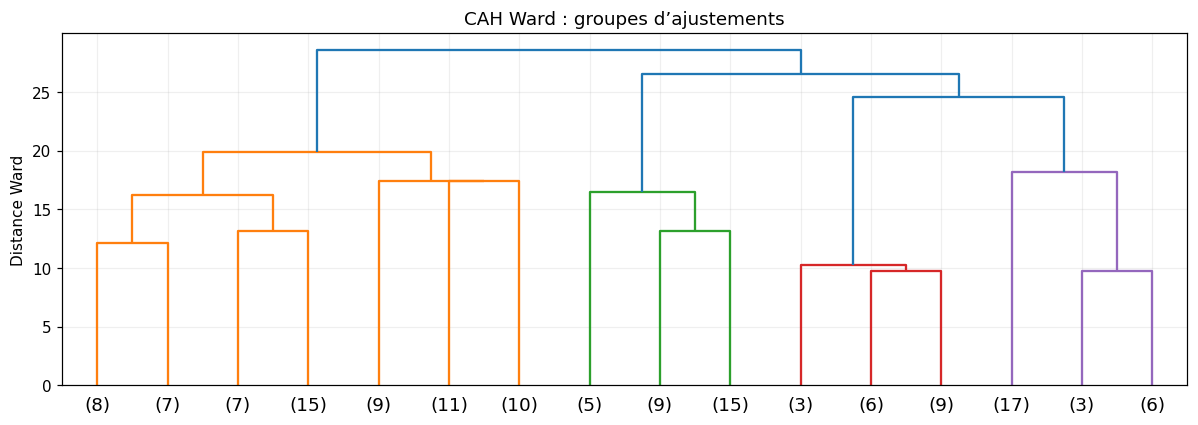

In [15]:
hierarchie_stock=linkage(X_stock_all,method='ward')
fig,ax=plt.subplots(figsize=(11,4))
dendrogram(hierarchie_stock,truncate_mode='lastp',p=16,ax=ax)
ax.set(title='CAH Ward : groupes d’ajustements',ylabel='Distance Ward')
plt.tight_layout();plt.show()

### d. Comparer les groupes


In [16]:
profils_stock['cluster_CAH']=AgglomerativeClustering(
    n_clusters=k_stock,linkage='ward').fit_predict(X_stock_all)
print('ARI :',round(adjusted_rand_score(
    profils_stock.cluster_KMeans,profils_stock.cluster_CAH),3))
display(pd.crosstab(profils_stock.cluster_KMeans,profils_stock.cluster_CAH))
display(profils_stock.groupby('cluster_KMeans')[
    ['rang_amplitude','signe_positif']].mean().round(2))
display(pd.crosstab(profils_stock.cluster_KMeans,profils_stock.item_category))

ARI : 0.575


cluster_CAH,0,1,2,3,4
cluster_KMeans,,,,,
0,2,0,0,0,12
1,20,0,0,0,0
2,1,30,0,0,20
3,1,0,0,18,0
4,2,0,29,0,5


,rang_amplitude,signe_positif
cluster_KMeans,,
0,0.54,0.64
1,0.52,0.60
2,0.51,0.20
3,0.53,0.53
4,0.51,0.28


item_category,agricultural_product,biological_sample,medical_consumables,monitoring_equipment,protective_equipment
cluster_KMeans,,,,,
0,0,0,0,0,14
1,0,0,0,20,0
2,0,0,51,0,0
3,19,0,0,0,0
4,0,36,0,0,0


**Interprétation des clusters :** K-Means retrouve surtout les **cinq catégories d’articles** : 14 ajustements d’équipements de protection, 20 d’équipements de suivi, 51 de consommables médicaux, 19 de produits agricoles et 36 d’échantillons biologiques. Cela signifie que le regroupement suit principalement les catégories, ce qui est logique puisqu’elles sont utilisées pour construire les profils. La comparaison avec la CAH donne un **ARI de 0,575** : les groupes ne sont pas identiques. Ce résultat décrit les types de mouvements, pas les anomalies à lui seul.


### e. ACP des clusters


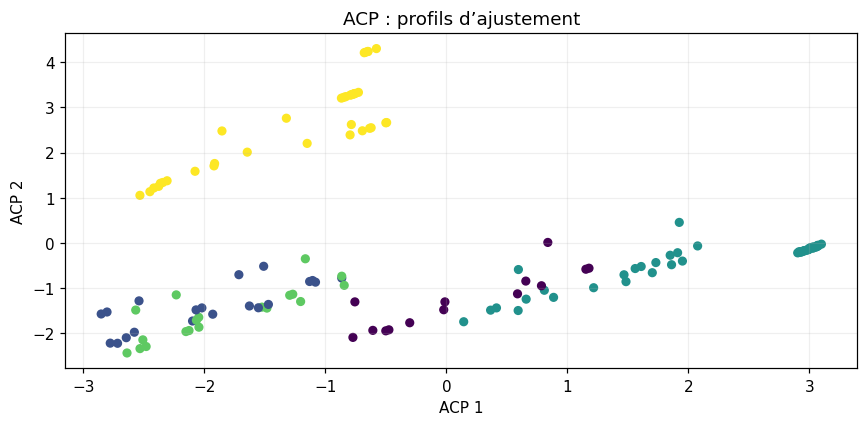

In [17]:
proj_stock_all=PCA(n_components=2).fit_transform(X_stock_all)
fig,ax=plt.subplots(figsize=(8,4))
ax.scatter(proj_stock_all[:,0],proj_stock_all[:,1],
           c=profils_stock.cluster_KMeans,s=25)
ax.set(title='ACP : profils d’ajustement',xlabel='ACP 1',ylabel='ACP 2')
plt.tight_layout();plt.show()

→ Lecture : comparaison des profils relatifs, pas des quantités dans des unités incompatibles.


# 4. ACP et t-SNE


### a. Choisir une unité comparable : medical_consumables / case


In [18]:
subset_stock=df.loc[(df.item_category=='medical_consumables') &
                    (df.unit=='case')].copy()
print('Ajustements comparables :',len(subset_stock))
stock_features=pd.DataFrame({
    'quantite':subset_stock.adjustment_quantity,
    'amplitude':np.log1p(subset_stock.adjustment_quantity.abs()),
    'statut_posted':subset_stock.adjustment_status.eq('posted').astype(int)},
    index=subset_stock.index)
X_stock=StandardScaler().fit_transform(stock_features)
assert len(subset_stock)>=20

Ajustements comparables : 51


### b. ACP


Variance expliquée : [0.403 0.379]


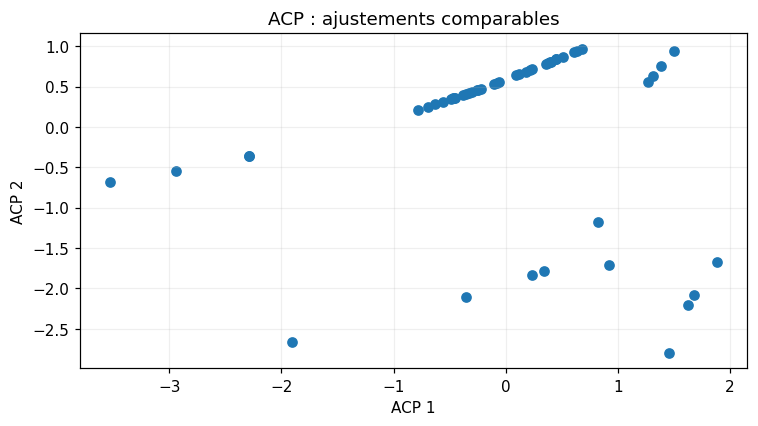

In [19]:
stock_acp=PCA(n_components=2).fit(X_stock)
points_stock=stock_acp.transform(X_stock)
print('Variance expliquée :',stock_acp.explained_variance_ratio_.round(3))
fig,ax=plt.subplots(figsize=(7,4));ax.scatter(points_stock[:,0],points_stock[:,1])
ax.set(title='ACP : ajustements comparables',xlabel='ACP 1',ylabel='ACP 2')
plt.tight_layout();plt.show()

### c. t-SNE


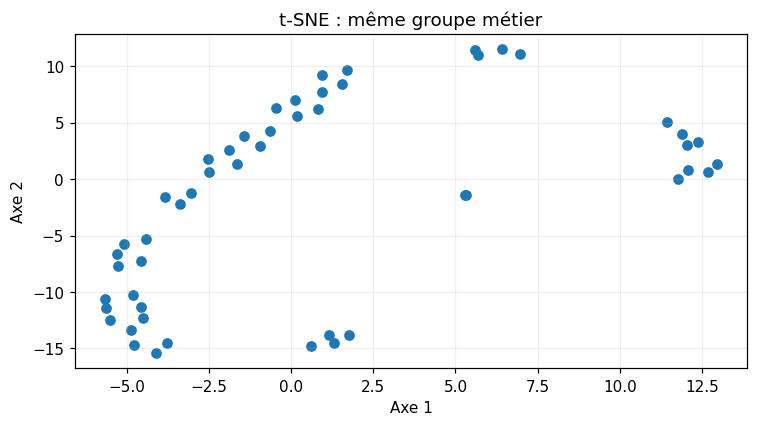

In [20]:
points_stock_tsne=TSNE(n_components=2,perplexity=8,init='random',
    learning_rate='auto',random_state=42).fit_transform(X_stock)
fig,ax=plt.subplots(figsize=(7,4))
ax.scatter(points_stock_tsne[:,0],points_stock_tsne[:,1])
ax.set(title='t-SNE : même groupe métier',xlabel='Axe 1',ylabel='Axe 2')
plt.tight_layout();plt.show()

**Lecture :** projection d’un groupe homogène uniquement ; les unités différentes ne sont pas mélangées.


# 5. Bloc 3 — Détection statistique des anomalies


**Pourquoi garder les valeurs atypiques ?** Un ajustement négatif signifie une diminution de stock : ce n’est pas une erreur en soi. Comme les produits et unités peuvent être très différents, nous comparons les quantités **à l’intérieur de la même catégorie et de la même unité**. Les valeurs extrêmes sont gardées pour pouvoir vérifier leur motif, leur statut et les pièces associées.


### Calculer les seuils IQR, Z-score et MAD


In [21]:
def seuils_pour_variable(x, min_n=8, haut_seul=False):
    valeurs = x.dropna()
    n = len(valeurs)
    q1, q3 = valeurs.quantile([.25, .75]) if n else (np.nan, np.nan)
    moyenne, ecart_type = valeurs.mean(), valeurs.std(ddof=1)
    mediane = valeurs.median()
    mad = (valeurs - mediane).abs().median()
    bornes = [
        ('IQR', q1-1.5*(q3-q1), q3+1.5*(q3-q1), x, q3-q1, 'hors Q1−1.5×IQR ; Q3+1.5×IQR'),
        ('Z-score', moyenne-3*ecart_type, moyenne+3*ecart_type,
         (x-moyenne)/ecart_type if ecart_type>0 else x*0+np.nan, ecart_type, '|z| > 3'),
        ('Z-modifie', mediane-3.5*mad/.6745, mediane+3.5*mad/.6745,
         .6745*(x-mediane)/mad if mad>0 else x*0+np.nan, mad, '|z_mod| > 3.5')]
    return n, bornes


### Identifier les observations atypiques


In [22]:
def lignes_signalees(g, cle, variable, groupe, min_n=8, haut_seul=False):
    x = pd.to_numeric(g[variable], errors='raise').replace([np.inf, -np.inf], np.nan)
    n, bornes = seuils_pour_variable(x, min_n, haut_seul)
    observations = []
    for methode, bas, haut, scores, ecart, regle in bornes:
        utilisable = n >= min_n and pd.notna(ecart) and ecart > 1e-12
        if haut_seul:
            bas = -np.inf
            regle += ' (queue haute uniquement)'
        for idx in g.index:
            valeur = x.loc[idx]
            applicable = bool(utilisable and pd.notna(valeur))
            observations.append(dict(
                observation=str(g.at[idx, cle]), groupe=groupe, variable=variable,
                methode=methode, valeur=valeur,
                score=scores.loc[idx] if applicable else np.nan,
                borne_basse=bas if utilisable else np.nan,
                borne_haute=haut if utilisable else np.nan, n_reference=n,
                applicable=applicable,
                signalee=bool(applicable and (valeur < bas or valeur > haut)),
                regle=regle if utilisable else f'Non évalué : n < {min_n} ou dispersion nulle',
                interpretation='Valeur atypique dans ce groupe ; contrôle du contexte nécessaire, pas une erreur établie.'))
    return observations


### Appliquer les tests statistiques


In [23]:
def statistiques(data, cle, variables, groupes=(), min_n=8, haut_seul=False):
    """IQR, Z et MAD par groupe comparable ; pas d'imputation."""
    tous = []
    parts = (data.groupby(list(groupes), dropna=False, sort=True)
             if groupes else [('ensemble', data)])
    for identifiant, part in parts:
        if groupes:
            valeurs = identifiant if isinstance(identifiant, tuple) else (identifiant,)
            etiquette = '; '.join(f'{col}={val}' for col, val in zip(groupes, valeurs))
        else:
            etiquette = 'ensemble'
        for variable in variables:
            tous.extend(lignes_signalees(part, cle, variable, etiquette, min_n, haut_seul))
    return pd.DataFrame(tous)


### Résumer les tests


In [24]:
def resume_tests(tests):
    display(
        tests.groupby(["variable", "methode"])
        .agg(evaluations=("applicable", "sum"), signalees=("signalee", "sum"))
        .reset_index()
    )
    skipped = tests.loc[
        ~tests.applicable, ["groupe", "variable", "methode", "regle"]
    ].drop_duplicates()
    if len(skipped):
        print("Cas non évalués (extrait) :")
        display(skipped.head(12))


In [25]:
tests_qty = statistiques(
    df,
    "adjustment_number",
    ["adjustment_quantity", "magnitude"],
    ["item_category", "unit"],
)
resume_tests(tests_qty)
signed_checks = statistiques(
    df, "adjustment_number", ["magnitude"], ["item_category", "unit", "signe"]
)
signed_checks["methode"] = signed_checks.methode + " (par signe)"
resume_tests(signed_checks)
quantity_ids = set(tests_qty.loc[tests_qty.signalee, "observation"]) | set(
    signed_checks.loc[signed_checks.signalee, "observation"]
)


Cas non évalués (extrait) :


,variable,methode,evaluations,signalees
0,adjustment_quantity,IQR,140,15
1,adjustment_quantity,Z-modifie,140,19
2,adjustment_quantity,Z-score,140,1
3,magnitude,IQR,140,7
4,magnitude,Z-modifie,140,7
5,magnitude,Z-score,140,1


,variable,methode,evaluations,signalees
0,magnitude,IQR (par signe),135,10
1,magnitude,Z-modifie (par signe),135,8
2,magnitude,Z-score (par signe),135,1


,groupe,variable,methode,regle
405,item_category=protective_equipment; unit=case; signe=diminution,magnitude,IQR (par signe),Non évalué : n < 8 ou dispersion nulle
410,item_category=protective_equipment; unit=case; signe=diminution,magnitude,Z-score (par signe),Non évalué : n < 8 ou dispersion nulle
415,item_category=protective_equipment; unit=case; signe=diminution,magnitude,Z-modifie (par signe),Non évalué : n < 8 ou dispersion nulle


In [26]:
display(
    df.loc[
        df.adjustment_number.isin(quantity_ids),
        [
            "adjustment_number",
            "adjustment_date",
            "facility_code",
            "item_category",
            "unit",
            "adjustment_quantity",
            "adjustment_reason",
            "adjustment_status",
        ],
    ].sort_values("adjustment_date")
)


,adjustment_number,adjustment_date,facility_code,item_category,unit,adjustment_quantity,adjustment_reason,adjustment_status
3,ADJ-2016-00004,2016-01-20,FCL-1007,biological_sample,sealed_lot,6.52,late receipt posting,pending_review
5,ADJ-2016-00006,2016-06-12,FCL-1004,medical_consumables,case,1.48,damaged packaging write-off,posted
15,ADJ-2018-00016,2018-02-22,FCL-1029,biological_sample,sealed_lot,-7.25,cycle count correction,posted
17,ADJ-2018-00018,2018-02-26,FCL-1029,biological_sample,sealed_lot,6.04,cycle count correction,approved
29,ADJ-2019-00030,2019-01-11,FCL-1015,biological_sample,sealed_lot,6.00,late receipt posting,approved
31,ADJ-2019-00032,2019-01-24,FCL-1022,medical_consumables,case,-5.86,cycle count correction,pending_review
47,ADJ-2019-00048,2019-11-12,FCL-1003,medical_consumables,case,2.25,cycle count correction,approved
48,ADJ-2019-00049,2019-11-21,FCL-1003,medical_consumables,case,-5.45,quality-hold release,posted
61,ADJ-2020-00062,2020-06-19,FCL-1008,biological_sample,sealed_lot,7.45,cycle count correction,pending_review
67,ADJ-2021-00068,2021-03-20,FCL-1017,medical_consumables,case,-5.44,unit-of-measure review,posted


### Examiner les plus grandes amplitudes


In [27]:
extremes = (
    df.sort_values("magnitude", ascending=False)
    .groupby(["item_category", "unit"])
    .head(2)
)


In [28]:
display(
    extremes[
        [
            "adjustment_number",
            "item_category",
            "unit",
            "adjustment_quantity",
            "adjustment_reason",
        ]
    ]
)


,adjustment_number,item_category,unit,adjustment_quantity,adjustment_reason
43,ADJ-2019-00044,agricultural_product,pallet,-7.91,transfer posting correction
96,ADJ-2022-00097,medical_consumables,case,-7.88,cycle count correction
108,ADJ-2023-00109,protective_equipment,case,7.87,quality-hold release
82,ADJ-2022-00083,monitoring_equipment,kit,7.74,transfer posting correction
35,ADJ-2019-00036,agricultural_product,pallet,-7.61,transfer posting correction
19,ADJ-2018-00020,monitoring_equipment,kit,7.58,transfer posting correction
61,ADJ-2020-00062,biological_sample,sealed_lot,7.45,cycle count correction
92,ADJ-2022-00093,medical_consumables,case,7.41,late receipt posting
130,ADJ-2025-00131,protective_equipment,case,-7.29,transfer posting correction
15,ADJ-2018-00016,biological_sample,sealed_lot,-7.25,cycle count correction


In [29]:
display(
    Markdown(
        f"**Lecture calculée :** {len(quantity_ids)} ajustements signalés sur les quantités dans "
        "au moins une comparaison. Les plus grandes amplitudes sont également affichées pour lecture manuelle ; "
        "un maximum n'est pas automatiquement une anomalie."
    )
)
large_magnitude = tests_qty.loc[
    tests_qty.variable.eq("magnitude")
    & tests_qty.signalee
    & tests_qty.valeur.gt(tests_qty.borne_haute),
    "observation",
].unique()


**Lecture calculée :** 23 ajustements signalés sur les quantités dans au moins une comparaison. Les plus grandes amplitudes sont également affichées pour lecture manuelle ; un maximum n'est pas automatiquement une anomalie.

### Analyser les observations signalées


In [30]:
display(
    Markdown(
        f"**Amplitudes importantes dans le groupe catégorie/unité :** {len(large_magnitude)} ajustements. Les détections sur la quantité signée incluent aussi des augmentations rares au milieu de diminutions habituelles ; elles ne mesurent pas toutes une grande amplitude."
    )
)


**Amplitudes importantes dans le groupe catégorie/unité :** 7 ajustements. Les détections sur la quantité signée incluent aussi des augmentations rares au milieu de diminutions habituelles ; elles ne mesurent pas toutes une grande amplitude.

In [31]:
display(
    df.loc[
        df.adjustment_number.isin(large_magnitude),
        [
            "adjustment_number",
            "item_category",
            "unit",
            "adjustment_quantity",
            "adjustment_reason",
        ],
    ]
)


,adjustment_number,item_category,unit,adjustment_quantity,adjustment_reason
31,ADJ-2019-00032,medical_consumables,case,-5.86,cycle count correction
48,ADJ-2019-00049,medical_consumables,case,-5.45,quality-hold release
67,ADJ-2021-00068,medical_consumables,case,-5.44,unit-of-measure review
92,ADJ-2022-00093,medical_consumables,case,7.41,late receipt posting
96,ADJ-2022-00097,medical_consumables,case,-7.88,cycle count correction
115,ADJ-2024-00116,medical_consumables,case,-6.68,damaged packaging write-off
131,ADJ-2025-00132,medical_consumables,case,5.55,quality-hold release


### Étudier les séries mensuelles


### Corriger les tests multiples (BH)


In [32]:
def bh(pvalues):
    """Benjamini–Hochberg : ajustement descriptif des comparaisons multiples."""
    pvalues = np.asarray(pvalues, dtype=float)
    result = np.full(len(pvalues), np.nan)
    good = np.flatnonzero(np.isfinite(pvalues))
    if len(good):
        order = good[np.argsort(pvalues[good])]
        adjusted = pvalues[order] * len(good) / np.arange(1, len(good) + 1)
        result[order] = np.minimum.accumulate(adjusted[::-1])[::-1].clip(0, 1)
    return result


### Construire les séries mensuelles


In [33]:
def frequences(data, facility, date):
    """Panel entre premier et dernier mois observés, y compris les zéros enregistrés."""
    frames = []
    for name, g in data.groupby(facility):
        periods = g[date].dt.to_period("M")
        grid = pd.period_range(periods.min(), periods.max(), freq="M")
        counts = periods.value_counts().reindex(grid, fill_value=0).sort_index()
        out = pd.DataFrame(
            {"etablissement": name, "mois": grid.to_timestamp(), "n": counts.values}
        )
        # Bords exclus : premier/dernier mois d'activité observée potentiellement incomplets.
        out["interieur"] = (np.arange(len(out)) > 0) & (
            np.arange(len(out)) < len(out) - 1
        )
        out["historique_12"] = out["n"].shift(1).rolling(12, min_periods=12).sum()
        past_complete = (
            out["interieur"].shift(1).rolling(12, min_periods=12).sum().eq(12)
        )
        out["eligible"] = out["interieur"] & past_complete
        out["p_pic"] = np.nan
        ix = out["eligible"]
        # Sous un taux constant, conditionnellement au total, le mois testé représente 1/13 de l'exposition.
        total = (out.loc[ix, "historique_12"] + out.loc[ix, "n"]).astype(int)
        out.loc[ix, "p_pic"] = binom.sf(out.loc[ix, "n"] - 1, total, 1 / 13)
        out["observation"] = str(name) + "|" + out["mois"].dt.strftime("%Y-%m")
        frames.append(out)
    out = pd.concat(frames, ignore_index=True)
    out["q_pic"] = bh(out.p_pic)
    out["pic_BH"] = out.q_pic.lt(0.05)
    return out


### Tester les pics mensuels


In [34]:
def test_pics(panel):
    result = pd.DataFrame(
        {
            "observation": panel.observation,
            "groupe": panel.etablissement,
            "variable": "nombre_mensuel",
            "methode": "Binomial_conditionnel_BH",
            "valeur": panel.n,
            "score": panel.q_pic,
            "historique_12": panel.historique_12,
            "p_brut": panel.p_pic,
            "borne_basse": 0.0,
            "borne_haute": 0.05,
            "n_reference": 12,
            "applicable": panel.eligible,
            "signalee": panel.pic_BH,
            "regle": "q_BH < 0.05 ; comparaison aux 12 mois précédents, bords exclus",
            "interpretation": "Pic exploratoire sous hypothèse de taux constant et couverture continue ; vérifier collecte et saisonnalité.",
        }
    )
    return result


In [35]:
facility_counts = df.facility_code.value_counts()
panel = frequences(df, "facility_code", "adjustment_date")
freq_stats = statistiques(
    panel.loc[panel.interieur],
    "observation",
    ["n"],
    ["etablissement"],
    min_n=12,
    haut_seul=True,
)
freq_tests = test_pics(panel)
resume_tests(freq_stats)
print("Fenêtres évaluables :", panel.eligible.sum())
print("Pics p<0.05 avant BH :", panel.p_pic.lt(0.05).sum())
print("Pics q<0.05 après BH :", panel.pic_BH.sum())


Cas non évalués (extrait) :
Fenêtres évaluables : 1437
Pics p<0.05 avant BH : 4
Pics q<0.05 après BH : 0


,variable,methode,evaluations,signalees
0,n,IQR,0,0
1,n,Z-modifie,0,0
2,n,Z-score,1342,31


,groupe,variable,methode,regle
0,etablissement=FCL-1001,n,IQR,Non évalué : n < 12 ou dispersion nulle
152,etablissement=FCL-1001,n,Z-modifie,Non évalué : n < 12 ou dispersion nulle
228,etablissement=FCL-1003,n,IQR,Non évalué : n < 12 ou dispersion nulle
358,etablissement=FCL-1003,n,Z-modifie,Non évalué : n < 12 ou dispersion nulle
423,etablissement=FCL-1004,n,IQR,Non évalué : n < 12 ou dispersion nulle
611,etablissement=FCL-1004,n,Z-modifie,Non évalué : n < 12 ou dispersion nulle
705,etablissement=FCL-1005,n,IQR,Non évalué : n < 12 ou dispersion nulle
775,etablissement=FCL-1005,n,Z-modifie,Non évalué : n < 12 ou dispersion nulle
810,etablissement=FCL-1006,n,IQR,Non évalué : n < 12 ou dispersion nulle
871,etablissement=FCL-1006,n,Z-score,Non évalué : n < 12 ou dispersion nulle


### ACF et STL : évolution mensuelle des ajustements


Période : 132 mois ; 80 sans ajustement enregistré


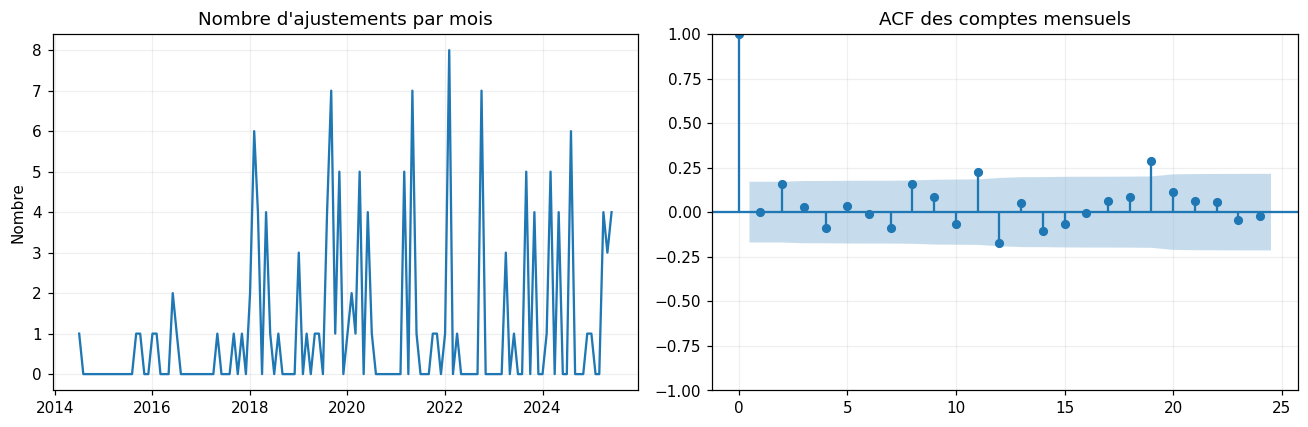

In [36]:
mois_ajustements = pd.period_range(df.month.min(), df.month.max(), freq="M")
serie_ajustements = df.groupby("month").size().reindex(mois_ajustements, fill_value=0)
serie_ajustements.index = serie_ajustements.index.to_timestamp()
print("Période :", len(serie_ajustements), "mois ;", int(serie_ajustements.eq(0).sum()), "sans ajustement enregistré")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(serie_ajustements.index, serie_ajustements.values)
axes[0].set(title="Nombre d'ajustements par mois", ylabel="Nombre")
plot_acf(serie_ajustements, lags=24, ax=axes[1], title="ACF des comptes mensuels")
plt.tight_layout();plt.show()


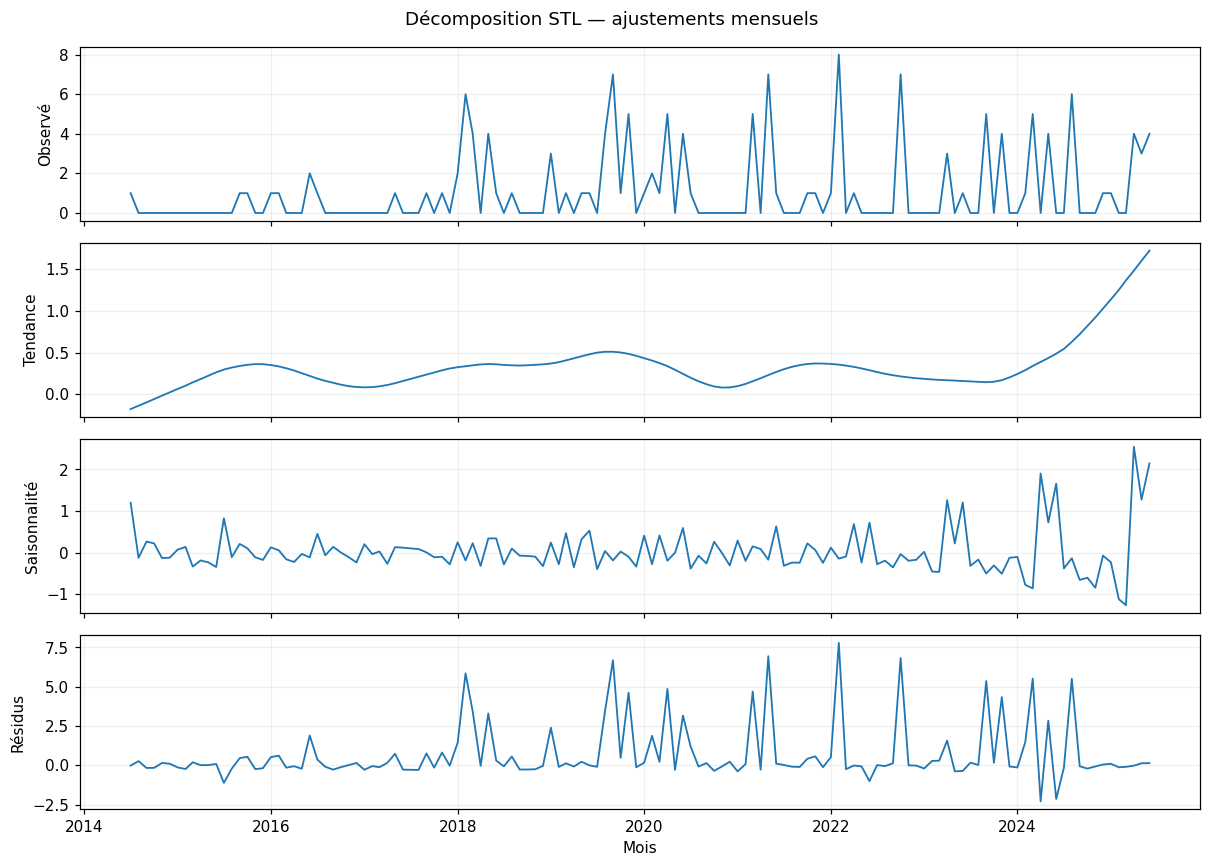

In [37]:
# STL uniquement à titre de description : les ajustements mensuels sont clairsemés.
assert len(serie_ajustements) >= 24
stl_ajustements = STL(serie_ajustements, period=12, robust=True).fit()
fig, axes = plt.subplots(4, 1, figsize=(11, 8), sharex=True)
for ax, values, titre in zip(axes,
        [serie_ajustements, stl_ajustements.trend, stl_ajustements.seasonal, stl_ajustements.resid],
        ["Observé", "Tendance", "Saisonnalité", "Résidus"]):
    ax.plot(serie_ajustements.index, values, linewidth=1.2)
    ax.set_ylabel(titre)
axes[-1].set_xlabel("Mois")
fig.suptitle("Décomposition STL — ajustements mensuels")
plt.tight_layout();plt.show()


**Lecture :** l’ACF vérifie si les comptes se ressemblent selon le décalage en mois. La STL sépare artificiellement ces comptes en composantes pour aider à les visualiser. Comme les événements sont rares et que les mois sans ligne sont supposés à zéro, **la saisonnalité et les résidus ne doivent pas être pris pour des anomalies métier confirmées**.


,observation,n,historique_12,p_pic,q_pic,pic_BH
13,FCL-1001|2019-04,0,0.0,1.000000,1.0,False
14,FCL-1001|2019-05,0,0.0,1.000000,1.0,False
15,FCL-1001|2019-06,0,0.0,1.000000,1.0,False
16,FCL-1001|2019-07,0,0.0,1.000000,1.0,False
17,FCL-1001|2019-08,1,0.0,0.076923,1.0,False
18,FCL-1001|2019-09,1,1.0,0.147929,1.0,False
19,FCL-1001|2019-10,0,2.0,1.000000,1.0,False
20,FCL-1001|2019-11,0,2.0,1.000000,1.0,False
21,FCL-1001|2019-12,0,2.0,1.000000,1.0,False
22,FCL-1001|2020-01,0,2.0,1.000000,1.0,False


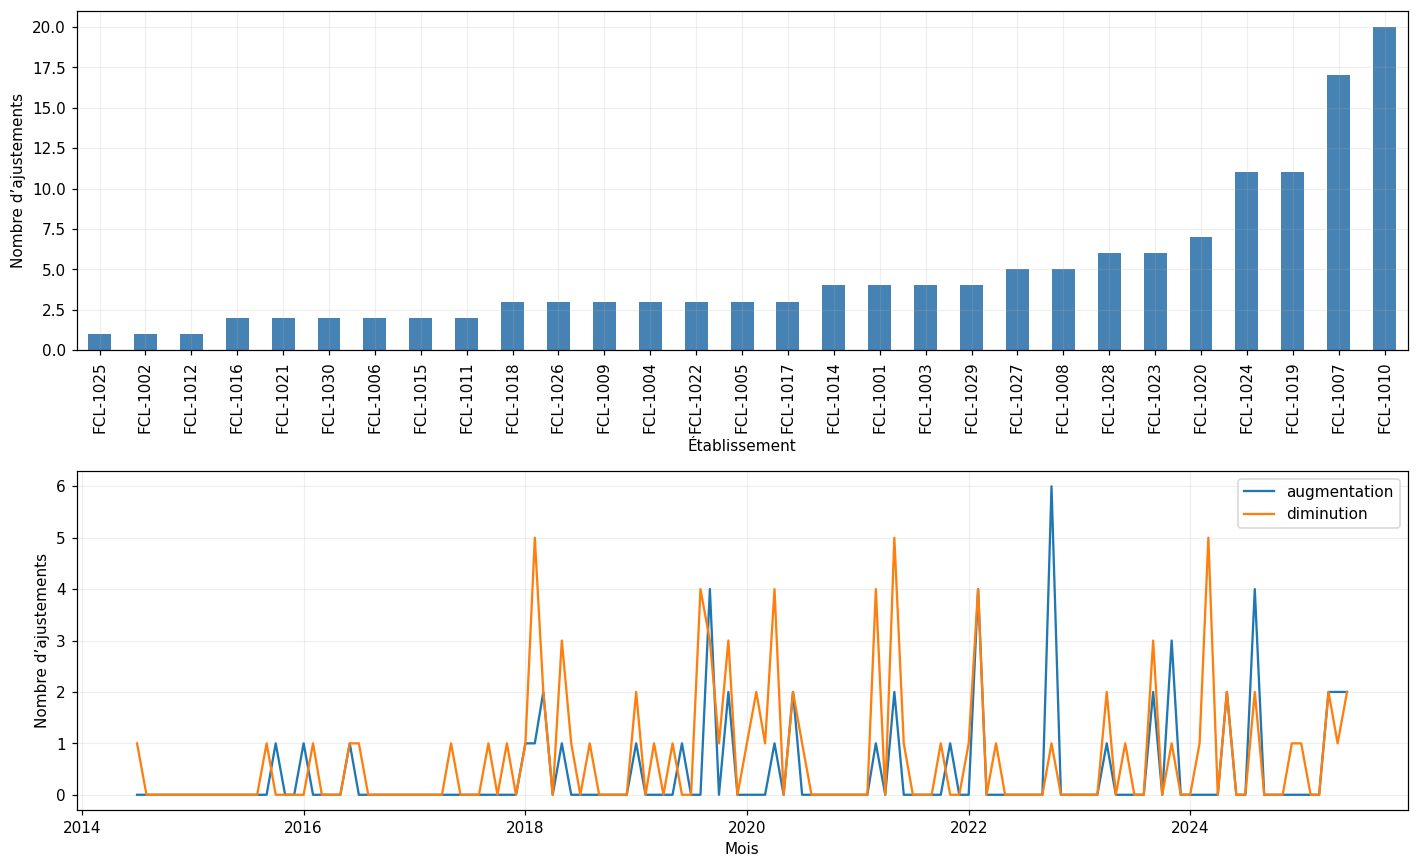

In [38]:
display(
    panel.loc[panel.eligible].nsmallest(12, "q_pic")[
        ["observation", "n", "historique_12", "p_pic", "q_pic", "pic_BH"]
    ]
)
fig, axes = plt.subplots(2, 1, figsize=(13, 8))
facility_counts.sort_values().plot.bar(ax=axes[0], color="steelblue")
axes[0].set_ylabel("Nombre d’ajustements")
axes[0].set_xlabel("Établissement")
months = pd.period_range(df.month.min(), df.month.max(), freq="M")
for sign, g in df.groupby("signe"):
    counts = g.month.value_counts().reindex(months, fill_value=0)
    axes[1].plot(months.to_timestamp(), counts, label=sign)
axes[1].set_xlabel("Mois")
axes[1].set_ylabel("Nombre d’ajustements")
axes[1].legend()
fig.tight_layout()
plt.show()


In [39]:
display(
    Markdown(
        "**Lecture :** les fréquences dépendent des pratiques de saisie et de la durée couverte. "
        "Aucun taux par quantité de stock ou par réception ne peut être déduit de ce seul fichier."
    )
)


**Lecture :** les fréquences dépendent des pratiques de saisie et de la durée couverte. Aucun taux par quantité de stock ou par réception ne peut être déduit de ce seul fichier.

### Préparer les détections


In [40]:
quantity_tests = pd.concat([tests_qty, signed_checks], ignore_index=True)


In [41]:
quantity_tests = quantity_tests.merge(
    df[
        [
            "adjustment_number",
            "adjustment_date",
            "facility_code",
            "adjustment_quantity",
            "item_category",
            "unit",
            "adjustment_reason",
            "signe",
        ]
    ],
    left_on="observation",
    right_on="adjustment_number",
    how="left",
    validate="many_to_one",
)


In [42]:
quantity_tests["observations_sources"] = quantity_tests.observation
monthly_tests = pd.concat([freq_stats, freq_tests], ignore_index=True)
members = df.groupby(["facility_code", "month"]).adjustment_number.agg(
    lambda x: "; ".join(x)
)
source_map = {
    row.observation: members.get(
        (row.etablissement, pd.Period(row.mois, freq="M")),
        "[aucun ajustement enregistré]",
    )
    for row in panel.itertuples()
}


### Tableau des anomalies


### Construire le tableau des anomalies


In [43]:
def bilan(tests, nom, domaine):
    """Affiche les anomalies et seuils dans le notebook, sans créer de CSV."""
    tests = tests.copy()
    tests["echelle_seuil"] = np.where(
        tests.methode.isin(
            ["Binomial_conditionnel_BH", "Fisher_exact_BH", "IF", "LOF", "LOF_k5"]
        ),
        "score",
        "valeur",
    )
    flagged = tests.loc[tests.signalee].copy()
    cols = [
        "groupe", "variable", "methode", "borne_basse", "borne_haute",
        "n_reference", "regle", "echelle_seuil",
    ]
    seuils = tests[cols].drop_duplicates().reset_index(drop=True)
    assert flagged.observation.notna().all()
    print(
        f"{len(flagged)} détections ; {flagged.observation.nunique()} identifiants distincts "
        "(plusieurs méthodes peuvent signaler une même observation)."
    )
    print("Anomalies détectées :")
    with pd.option_context("display.max_rows", None, "display.max_columns", None):
        display(flagged.reset_index(drop=True))
    print(f"Seuils utilisés : {len(seuils)} combinaisons (premières 20 lignes) :")
    display(seuils.head(20))
    return flagged


In [44]:
monthly_tests["observations_sources"] = monthly_tests.observation.map(source_map)
all_tests = pd.concat([quantity_tests, monthly_tests], ignore_index=True)
all_tests.loc[all_tests.variable.eq("adjustment_quantity"), "interpretation"] = (
    "Quantité signée rare dans la catégorie/unité ; peut refléter une augmentation légitime dans un groupe dominé par les diminutions."
)
all_tests.loc[all_tests.variable.eq("magnitude"), "interpretation"] = (
    "Amplitude rare dans le groupe indiqué ; vérifier si elle est haute ou basse et la taille du stock concerné."
)
register = bilan(all_tests, "inventory_adjustments", "logistics")


100 détections ; 54 identifiants distincts (plusieurs méthodes peuvent signaler une même observation).
Anomalies détectées :
Seuils utilisés : 167 combinaisons (premières 20 lignes) :


,observation,groupe,variable,methode,valeur,score,borne_basse,borne_haute,n_reference,...,adjustment_quantity,item_category,unit,adjustment_reason,signe,observations_sources,historique_12,p_brut,echelle_seuil
0,ADJ-2016-00004,item_category=biological_sample; unit=sealed_lot,adjustment_quantity,Z-modifie,6.52,3.798052,-10.629611,5.819611,36,...,6.52,biological_sample,sealed_lot,late receipt posting,augmentation,ADJ-2016-00004,NaN,NaN,valeur
1,ADJ-2018-00018,item_category=biological_sample; unit=sealed_lot,adjustment_quantity,Z-modifie,6.04,3.593787,-10.629611,5.819611,36,...,6.04,biological_sample,sealed_lot,cycle count correction,augmentation,ADJ-2018-00018,NaN,NaN,valeur
2,ADJ-2019-00030,item_category=biological_sample; unit=sealed_lot,adjustment_quantity,Z-modifie,6.00,3.576765,-10.629611,5.819611,36,...,6.00,biological_sample,sealed_lot,late receipt posting,augmentation,ADJ-2019-00030,NaN,NaN,valeur
3,ADJ-2020-00062,item_category=biological_sample; unit=sealed_lot,adjustment_quantity,Z-modifie,7.45,4.193815,-10.629611,5.819611,36,...,7.45,biological_sample,sealed_lot,cycle count correction,augmentation,ADJ-2020-00062,NaN,NaN,valeur
4,ADJ-2016-00006,item_category=medical_consumables; unit=case,adjustment_quantity,IQR,1.48,1.480000,-4.327500,0.372500,51,...,1.48,medical_consumables,case,damaged packaging write-off,augmentation,ADJ-2016-00006,NaN,NaN,valeur
5,ADJ-2019-00032,item_category=medical_consumables; unit=case,adjustment_quantity,IQR,-5.86,-5.860000,-4.327500,0.372500,51,...,-5.86,medical_consumables,case,cycle count correction,diminution,ADJ-2019-00032,NaN,NaN,valeur
6,ADJ-2019-00048,item_category=medical_consumables; unit=case,adjustment_quantity,IQR,2.25,2.250000,-4.327500,0.372500,51,...,2.25,medical_consumables,case,cycle count correction,augmentation,ADJ-2019-00048,NaN,NaN,valeur
7,ADJ-2019-00049,item_category=medical_consumables; unit=case,adjustment_quantity,IQR,-5.45,-5.450000,-4.327500,0.372500,51,...,-5.45,medical_consumables,case,quality-hold release,diminution,ADJ-2019-00049,NaN,NaN,valeur
8,ADJ-2021-00068,item_category=medical_consumables; unit=case,adjustment_quantity,IQR,-5.44,-5.440000,-4.327500,0.372500,51,...,-5.44,medical_consumables,case,unit-of-measure review,diminution,ADJ-2021-00068,NaN,NaN,valeur
9,ADJ-2022-00086,item_category=medical_consumables; unit=case,adjustment_quantity,IQR,1.07,1.070000,-4.327500,0.372500,51,...,1.07,medical_consumables,case,quality-hold release,augmentation,ADJ-2022-00086,NaN,NaN,valeur


,groupe,variable,methode,borne_basse,borne_haute,n_reference,regle,echelle_seuil
0,item_category=agricultural_product; unit=pallet,adjustment_quantity,IQR,-11.892500,11.007500,19,hors Q1−1.5×IQR ; Q3+1.5×IQR,valeur
1,item_category=agricultural_product; unit=pallet,adjustment_quantity,Z-score,-13.120991,12.224149,19,|z| > 3,valeur
2,item_category=agricultural_product; unit=pallet,adjustment_quantity,Z-modifie,-16.538918,18.538918,19,|z_mod| > 3.5,valeur
3,item_category=agricultural_product; unit=pallet,magnitude,IQR,-1.467500,8.232500,19,hors Q1−1.5×IQR ; Q3+1.5×IQR,valeur
4,item_category=agricultural_product; unit=pallet,magnitude,Z-score,-2.756667,9.931404,19,|z| > 3,valeur
5,item_category=agricultural_product; unit=pallet,magnitude,Z-modifie,-2.783603,8.943603,19,|z_mod| > 3.5,valeur
6,item_category=biological_sample; unit=sealed_lot,adjustment_quantity,IQR,-10.631250,7.978750,36,hors Q1−1.5×IQR ; Q3+1.5×IQR,valeur
7,item_category=biological_sample; unit=sealed_lot,adjustment_quantity,Z-score,-13.578778,10.850444,36,|z| > 3,valeur
8,item_category=biological_sample; unit=sealed_lot,adjustment_quantity,Z-modifie,-10.629611,5.819611,36,|z_mod| > 3.5,valeur
9,item_category=biological_sample; unit=sealed_lot,magnitude,IQR,-1.895000,9.185000,36,hors Q1−1.5×IQR ; Q3+1.5×IQR,valeur


In [45]:
summary = {
    "n": len(df),
    "negative": int(df.adjustment_quantity.lt(0).sum()),
    "positive": int(df.adjustment_quantity.gt(0).sum()),
    "quantity_flags": len(quantity_ids),
    "large_magnitude": len(large_magnitude),
    "quantity_ids": sorted(quantity_ids),
    "conditional_peaks": int(panel.pic_BH.sum()),
    "stats_months": int(freq_stats.loc[freq_stats.signalee, "observation"].nunique()),
    "top_facility": facility_counts.index[0],
    "top_facility_count": int(facility_counts.iloc[0]),
}


In [46]:
display(
    Markdown(
        f"**Bilan calculé :** {len(df)} ajustements, dont {summary['negative']} négatifs et "
        f"{summary['positive']} positifs. {summary['quantity_flags']} ajustements signalés sur les quantités ; "
        f"{summary['stats_months']} mois par IQR/Z ; {summary['conditional_peaks']} pics de fréquence après BH. "
        f"{summary['top_facility']} a le plus d'événements enregistrés ({summary['top_facility_count']}). "
        "Ce volume ne prouve pas un dysfonctionnement : on ignore ici son activité totale."
    )
)


**Bilan calculé :** 140 ajustements, dont 89 négatifs et 51 positifs. 23 ajustements signalés sur les quantités ; 31 mois par IQR/Z ; 0 pics de fréquence après BH. FCL-1010 a le plus d'événements enregistrés (20). Ce volume ne prouve pas un dysfonctionnement : on ignore ici son activité totale.

### Contrôler les calculs


In [47]:
assert panel.n.sum() == len(df)
assert df.adjustment_number.is_unique and len(df) == len(raw)
assert panel.loc[panel.pic_BH, "eligible"].all()


### Rapprocher les références documentaires


In [48]:
receipts = pd.read_csv(
    ROOT / "data/logistics/cleaned/goods_receipts_cleaned.csv",
    usecols=["receipt_number", "receipt_date"],
)
shipments = pd.read_csv(
    ROOT / "data/logistics/cleaned/shipments_clean.csv",
    usecols=["shipment_number", "dispatch_time"],
)
receipts["receipt_date"] = pd.to_datetime(receipts.receipt_date, errors="raise")
shipments["dispatch_time"] = pd.to_datetime(shipments.dispatch_time, errors="raise")
assert receipts.receipt_number.is_unique
first_departure = shipments.groupby(
    "shipment_number", as_index=False
).dispatch_time.min()


In [49]:
refs = df[
    [
        "adjustment_number",
        "adjustment_date",
        "facility_code",
        "adjustment_reason",
        "related_receipt_number",
        "related_shipment_number",
    ]
].copy()


In [50]:
refs = refs.merge(
    receipts,
    left_on="related_receipt_number",
    right_on="receipt_number",
    how="left",
    validate="many_to_one",
)


### Vérifier les dates liées


In [51]:
refs = refs.merge(
    first_departure,
    left_on="related_shipment_number",
    right_on="shipment_number",
    how="left",
    validate="many_to_one",
)
assert len(refs) == len(df)


In [52]:
for source, target, date in [
    ("réception", "related_receipt_number", "receipt_date"),
    ("expédition", "related_shipment_number", "dispatch_time"),
]:
    has_ref = refs[target].notna()
    known = refs[date].notna()
    future = (
        has_ref
        & known
        & (refs[date].dt.normalize() > refs.adjustment_date.dt.normalize())
    )
    refs["future_" + date] = future
    print(
        f"{source} : {has_ref.sum()} références ; {(has_ref & ~known).sum()} introuvables ; {future.sum()} événements datés après l’ajustement"
    )


réception : 23 références ; 0 introuvables ; 11 événements datés après l’ajustement
expédition : 37 références ; 0 introuvables ; 13 événements datés après l’ajustement


In [53]:
print(
    "Ajustements ayant au moins une référence future :",
    int(refs[["future_receipt_date", "future_dispatch_time"]].any(axis=1).sum()),
)


Ajustements ayant au moins une référence future : 21


In [54]:
display(
    refs.loc[
        refs[["future_receipt_date", "future_dispatch_time"]].any(axis=1),
        [
            "adjustment_number",
            "adjustment_date",
            "related_receipt_number",
            "receipt_date",
            "related_shipment_number",
            "dispatch_time",
        ],
    ].head(20)
)


,adjustment_number,adjustment_date,related_receipt_number,receipt_date,related_shipment_number,dispatch_time
2,ADJ-2015-00003,2015-10-30,RCV-2022-00361,2022-08-25,NaN,NaT
5,ADJ-2016-00006,2016-06-12,RCV-2024-00527,2024-07-04,NaN,NaT
13,ADJ-2018-00014,2018-02-18,RCV-2023-00414,2023-04-16,SHP-2023-00029,2023-04-22 09:00:00
15,ADJ-2018-00016,2018-02-22,RCV-2024-00522,2024-07-06,SHP-2025-00012,2025-05-05 16:00:00
16,ADJ-2018-00017,2018-02-23,RCV-2017-00054,2017-02-17,SHP-2024-00012,2024-06-01 05:00:00
17,ADJ-2018-00018,2018-02-26,RCV-2023-00446,2023-09-15,SHP-2023-00037,2023-09-01 05:00:00
35,ADJ-2019-00036,2019-08-13,RCV-2022-00342,2022-03-26,NaN,NaT
36,ADJ-2019-00037,2019-08-18,RCV-2020-00186,2020-02-18,NaN,NaT
37,ADJ-2019-00038,2019-08-19,RCV-2024-00497,2024-05-02,NaN,NaT
40,ADJ-2019-00041,2019-09-12,NaN,NaT,SHP-2021-00017,2021-05-11 09:00:00


### Résumer les anomalies de chronologie


In [55]:
print(
    "Ces écarts exigent de clarifier le sens métier des références ; ils ne prouvent pas une manipulation."
)


Ces écarts exigent de clarifier le sens métier des références ; ils ne prouvent pas une manipulation.


### Graphe des références des ajustements


In [56]:
# Graphe non orienté : un ajustement est relié à ses documents de réception/expédition.
liens = []
for r in df.itertuples():
    if pd.notna(r.related_receipt_number):
        liens.append(("ADJ:" + r.adjustment_number, "RCV:" + str(r.related_receipt_number)))
    if pd.notna(r.related_shipment_number):
        liens.append(("ADJ:" + r.adjustment_number, "SHP:" + str(r.related_shipment_number)))
noeuds = sorted(set(x for a, b in liens for x in (a, b)))
positions = {code: idx for idx, code in enumerate(noeuds)}
lignes = [positions[a] for a, b in liens] + [positions[b] for a, b in liens]
colonnes = [positions[b] for a, b in liens] + [positions[a] for a, b in liens]
adjacence = csr_matrix((np.ones(len(lignes), dtype=int), (lignes, colonnes)),
                       shape=(len(noeuds), len(noeuds)))
n_composantes, etiquette = connected_components(adjacence, directed=False)
tailles = pd.Series(etiquette).value_counts().sort_values(ascending=False)
print("Liens :", len(liens), "| Nœuds concernés :", len(noeuds),
      "| Composantes :", n_composantes)
display(tailles.value_counts().sort_index().rename_axis("taille_composante")
        .to_frame("nombre_composantes"))


Liens : 60 | Nœuds concernés : 115 | Composantes : 55


,nombre_composantes
taille_composante,
2,50
3,5


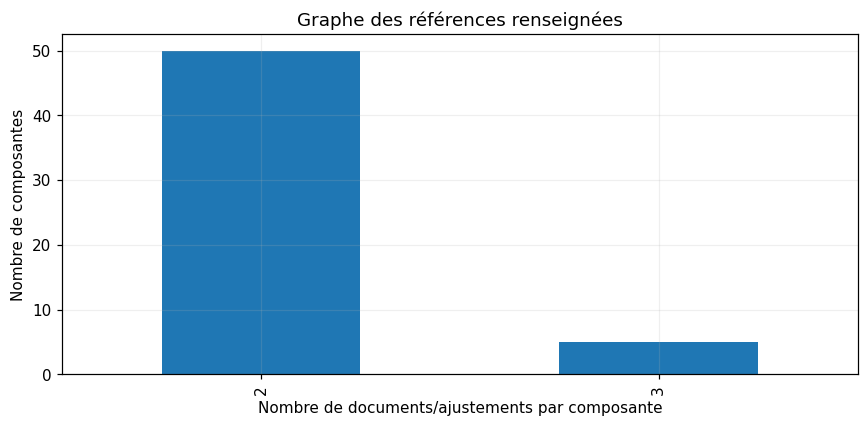

In [57]:
fig, ax = plt.subplots(figsize=(8, 4))
tailles.value_counts().sort_index().plot.bar(ax=ax)
ax.set(xlabel="Nombre de documents/ajustements par composante",
       ylabel="Nombre de composantes", title="Graphe des références renseignées")
plt.tight_layout();plt.show()


**Lecture :** ce graphe permet de voir si plusieurs ajustements partagent un même document ou si les références sont isolées. Les ajustements sans référence ne figurent pas dans ce graphe. Une composante relie des identifiants documentaires : **elle ne prouve pas un flux physique ni une chronologie correcte**.


# 6. Isolation Forest, LOF et DBSCAN


### Isolation Forest


In [58]:
if_stock=IsolationForest(n_estimators=200,contamination=.05,random_state=42)
subset_stock['IF_flag']=if_stock.fit_predict(X_stock)==-1
print('IF :',int(subset_stock.IF_flag.sum()),'cas signalés')

IF : 3 cas signalés


### LOF


In [59]:
lof_stock=LocalOutlierFactor(n_neighbors=10,contamination='auto')
lof_stock.fit_predict(X_stock)
subset_stock['LOF_score']=-lof_stock.negative_outlier_factor_
subset_stock['LOF_flag']=subset_stock.LOF_score.gt(1.5)
print('LOF :',int(subset_stock.LOF_flag.sum()),'cas signalés')

LOF : 18 cas signalés


### DBSCAN


In [60]:
labels_stock=DBSCAN(eps=1.3,min_samples=4).fit_predict(X_stock)
subset_stock['DBSCAN_bruit']=labels_stock==-1
print('DBSCAN :',int(subset_stock.DBSCAN_bruit.sum()),'points isolés')

DBSCAN : 6 points isolés


### Comparer les détections


In [61]:
display(subset_stock.loc[
    subset_stock.IF_flag | subset_stock.LOF_flag | subset_stock.DBSCAN_bruit,
    ['adjustment_number','adjustment_quantity','IF_flag','LOF_flag','DBSCAN_bruit']])

,adjustment_number,adjustment_quantity,IF_flag,LOF_flag,DBSCAN_bruit
5,ADJ-2016-00006,1.48,False,True,False
31,ADJ-2019-00032,-5.86,True,True,True
47,ADJ-2019-00048,2.25,False,True,False
48,ADJ-2019-00049,-5.45,False,True,False
67,ADJ-2021-00068,-5.44,False,True,False
68,ADJ-2021-00069,-2.32,False,True,True
78,ADJ-2021-00079,-3.00,False,True,False
85,ADJ-2022-00086,1.07,False,True,False
92,ADJ-2022-00093,7.41,True,True,True
93,ADJ-2022-00094,1.60,False,True,False


**Lecture :** quantité et amplitude sont liées ; plusieurs signaux ne sont pas des preuves indépendantes.


# 7. Associations entre modalités


In [62]:
transactions = []
for record in df.itertuples():
    transactions.append(
        frozenset(
            [
                "motif=" + str(record.adjustment_reason),
                "categorie=" + str(record.item_category),
                "signe=" + str(record.signe),
                "statut=" + str(record.adjustment_status),
            ]
        )
    )
n_trans = len(transactions)


In [63]:
assert n_trans == 140
count_items = Counter(item for basket in transactions for item in basket)
minimum_support = 0.08
frequent = {item for item, n in count_items.items() if n / n_trans >= minimum_support}
pairs = Counter(
    pair
    for basket in transactions
    for pair in combinations(sorted(basket & frequent), 2)
)
association_rules = []


In [64]:
for pair, count in pairs.items():
    support = count / n_trans
    if support < minimum_support:
        continue
    for a, b in [pair, pair[::-1]]:
        confidence = count / count_items[a]
        lift = confidence / (count_items[b] / n_trans)
        if confidence >= 0.6 and lift >= 1.2:
            association_rules.append(
                {
                    "antecedent": a,
                    "consequent": b,
                    "effectif": count,
                    "support": support,
                    "confiance": confidence,
                    "lift": lift,
                }
            )


### Support, confiance et lift


In [65]:
rules_df = pd.DataFrame(
    association_rules,
    columns=["antecedent", "consequent", "effectif", "support", "confiance", "lift"],
)


,antecedent,consequent,effectif,support,confiance,lift
0,statut=approved,signe=augmentation,17,0.121,0.680,1.867
1,categorie=monitoring_equipment,signe=augmentation,12,0.086,0.600,1.647
2,categorie=medical_consumables,statut=posted,43,0.307,0.843,1.312
3,categorie=medical_consumables,signe=diminution,41,0.293,0.804,1.265
4,statut=posted,signe=diminution,69,0.493,0.767,1.206
5,signe=diminution,statut=posted,69,0.493,0.775,1.206


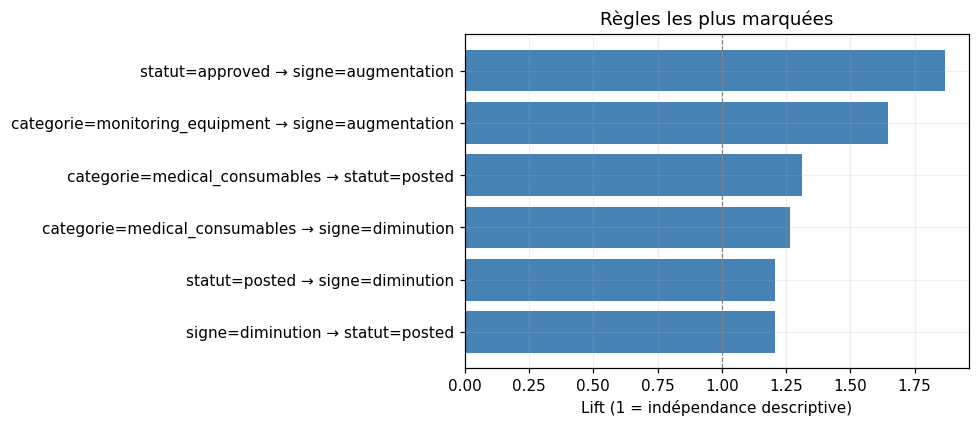

In [66]:
if rules_df.empty:
    print(
        "Aucune règle ne dépasse simultanément les trois seuils : résultat négatif conservé."
    )
else:
    rules_df = rules_df.sort_values(["lift", "support"], ascending=False).reset_index(
        drop=True
    )
    display(rules_df.head(15).round(3))
    fig, ax = plt.subplots(figsize=(9, 4))
    top = rules_df.head(8).iloc[::-1]
    ax.barh(top.antecedent + " → " + top.consequent, top.lift, color="steelblue")
    ax.axvline(1, color="gray", linestyle="--", linewidth=0.8)
    ax.set(
        xlabel="Lift (1 = indépendance descriptive)", title="Règles les plus marquées"
    )
    plt.tight_layout()
    plt.show()


In [67]:
print(
    "Interprétation : association descriptive des modalités, sans lien démontré avec les références documentaires atypiques."
)


Interprétation : association descriptive des modalités, sans lien démontré avec les références documentaires atypiques.


# 8. Apriori et croisements


### Construire les paniers d’ajustements


In [68]:
seuils_stock=df.groupby(['item_category','unit']).magnitude.transform(
    lambda x:x.quantile(.9))
paniers_stock=[]
for idx,r in df.iterrows():
    paniers_stock.append({
        'categorie='+str(r.item_category),
        'unite='+str(r.unit),
        'motif='+str(r.adjustment_reason),
        'statut='+str(r.adjustment_status),
        'signe='+('positif' if r.adjustment_quantity>0 else 'negatif'),
        'amplitude='+('haute' if r.magnitude>seuils_stock.loc[idx] else 'ordinaire')})
print('Ajustements :',len(paniers_stock))

Ajustements : 140


### Rechercher les ensembles fréquents


In [69]:
def apriori_itemsets(transactions, min_support=.08, max_size=3):
    """Apriori : construire et élaguer des ensembles fréquents de taille 1 à 3."""
    paniers=[set(t) for t in transactions]
    n=len(paniers)
    counts=Counter(item for panier in paniers for item in panier)
    freq={frozenset([x]):v/n for x,v in counts.items() if v/n>=min_support}
    all_freq=dict(freq)
    for k in range(2,max_size+1):
        uniques=sorted(set().union(*[set(f) for f in freq])) if freq else []
        candidates=(frozenset(combo) for combo in combinations(uniques,k))
        candidates=[c for c in candidates if all(frozenset(s) in freq
                        for s in combinations(c,k-1))]
        freq={c:sum(c<=panier for panier in paniers)/n for c in candidates}
        freq={c:s for c,s in freq.items() if s>=min_support}
        all_freq.update(freq)
    return all_freq

In [70]:
freq_stock=apriori_itemsets(paniers_stock, min_support=0.1, max_size=3)
print('Ensembles fréquents :',len(freq_stock))

Ensembles fréquents : 80


### Lire les règles d’association


In [71]:
def regles_apriori(freq, min_confiance=.6, min_lift=1.1):
    """Extraire support, confiance et lift pour toutes les règles fréquentes."""
    lignes=[]
    for ensemble,support in freq.items():
        if len(ensemble)<2:continue
        for taille in range(1,len(ensemble)):
            for part in combinations(sorted(ensemble),taille):
                gauche=frozenset(part);droite=ensemble-gauche
                confiance=support/freq[gauche]
                lift=confiance/freq[droite]
                if confiance>=min_confiance and lift>=min_lift:
                    lignes.append({'antecedent':' + '.join(sorted(gauche)),
                        'consequent':' + '.join(sorted(droite)),
                        'support':support,'confiance':confiance,'lift':lift})
    return pd.DataFrame(lignes,columns=['antecedent','consequent',
                                        'support','confiance','lift'])

In [72]:
regles_stock=regles_apriori(freq_stock)
print('Règles retenues :',len(regles_stock))
display(regles_stock.sort_values('lift',ascending=False).head(12).round(3))
regles_metier=regles_stock.loc[regles_stock.antecedent.str.contains("motif=|signe=|statut=") | regles_stock.consequent.str.contains("motif=|signe=|statut=")]
print("Règles avec motif, signe ou statut :",len(regles_metier))
display(regles_metier.sort_values("lift",ascending=False).head(10).round(3))


Règles retenues : 83
Règles avec motif, signe ou statut : 58


,antecedent,consequent,support,confiance,lift
0,categorie=agricultural_product,unite=pallet,0.136,1.000,7.368
21,amplitude=ordinaire + unite=pallet,categorie=agricultural_product,0.121,1.000,7.368
20,amplitude=ordinaire + categorie=agricultural_product,unite=pallet,0.121,1.000,7.368
1,unite=pallet,categorie=agricultural_product,0.136,1.000,7.368
19,unite=pallet,amplitude=ordinaire + categorie=agricultural_product,0.121,0.895,7.368
18,categorie=agricultural_product,amplitude=ordinaire + unite=pallet,0.121,0.895,7.368
9,categorie=monitoring_equipment,unite=kit,0.143,1.000,7.000
10,unite=kit,categorie=monitoring_equipment,0.143,1.000,7.000
36,categorie=monitoring_equipment,amplitude=ordinaire + unite=kit,0.129,0.900,7.000
37,unite=kit,amplitude=ordinaire + categorie=monitoring_equipment,0.129,0.900,7.000


,antecedent,consequent,support,confiance,lift
57,categorie=biological_sample + signe=negatif,unite=sealed_lot,0.186,1.000,3.889
56,unite=sealed_lot,categorie=biological_sample + signe=negatif,0.186,0.722,3.889
59,signe=negatif + unite=sealed_lot,categorie=biological_sample,0.186,1.000,3.889
60,categorie=biological_sample,statut=posted + unite=sealed_lot,0.171,0.667,3.889
61,unite=sealed_lot,categorie=biological_sample + statut=posted,0.171,0.667,3.889
62,categorie=biological_sample + statut=posted,unite=sealed_lot,0.171,1.000,3.889
63,statut=posted + unite=sealed_lot,categorie=biological_sample,0.171,1.000,3.889
55,categorie=biological_sample,signe=negatif + unite=sealed_lot,0.186,0.722,3.889
67,categorie=medical_consumables,signe=negatif + unite=case,0.293,0.804,2.447
71,signe=negatif + unite=case,categorie=medical_consumables,0.293,0.891,2.447


→ Résultat exploratoire : une association fréquente ne prouve pas une cause.


### Croiser anomalies et chronologie


In [73]:
alerts_stock=df[['adjustment_number','item_category','unit']].copy()
alerts_stock['anomalie_quantite']=alerts_stock.adjustment_number.isin(quantity_ids)
flags_dates=refs[['adjustment_number','receipt_date','dispatch_time',
                  'adjustment_date']].copy()
flags_dates['date_reception_future']=(flags_dates.receipt_date.dt.normalize() > flags_dates.adjustment_date.dt.normalize())
flags_dates['date_expedition_future']=(flags_dates.dispatch_time.dt.normalize() > flags_dates.adjustment_date.dt.normalize())
flags_dates['chronologie_a_verifier']=(flags_dates.date_reception_future |
    flags_dates.date_expedition_future)
alerts_stock=alerts_stock.merge(flags_dates[['adjustment_number',
    'chronologie_a_verifier']],on='adjustment_number',validate='one_to_one')
display(pd.crosstab(alerts_stock.anomalie_quantite,alerts_stock.chronologie_a_verifier))
display(alerts_stock.loc[alerts_stock.anomalie_quantite &
    alerts_stock.chronologie_a_verifier])

chronologie_a_verifier,False,True
anomalie_quantite,,
False,101,16
True,18,5


,adjustment_number,item_category,unit,anomalie_quantite,chronologie_a_verifier
5,ADJ-2016-00006,medical_consumables,case,True,True
15,ADJ-2018-00016,biological_sample,sealed_lot,True,True
17,ADJ-2018-00018,biological_sample,sealed_lot,True,True
73,ADJ-2021-00074,biological_sample,sealed_lot,True,True
76,ADJ-2021-00077,agricultural_product,pallet,True,True


→ Une date liée postérieure exige vérification du sens du lien métier.


# 9. Bilan final


### Ce qu’on a trouvé

Nous avons étudié **140 ajustements de stock**, dont **89 diminutions et 51 augmentations**. Il faut tenir compte de la catégorie et de l’unité avant de comparer les quantités : une valeur négative est normale lorsqu’on retire du stock.

Les tests sur les quantités signalent **23 ajustements**, dont **7 amplitudes particulièrement élevées** dans le groupe `medical_consumables / case`. Les séries mensuelles signalent aussi certains mois avec le Z-score, mais **aucun pic ne reste significatif après la correction BH**. Avec K-Means, on obtient cinq groupes qui correspondent principalement aux catégories d’articles.

Nous avons également vérifié les références vers les réceptions et expéditions. Toutes les références renseignées sont retrouvées, mais **21 ajustements distincts** mentionnent au moins un événement daté après l’ajustement. Cela mérite un contrôle de la chronologie et du sens des champs `related_*`.

### Ce qu’on en conclut

Ces détections nous donnent des **pistes de vérification**, pas des preuves d’erreurs ou de manipulations. Il faudrait relire en priorité les ajustements d’amplitude élevée et les 21 références chronologiquement surprenantes, puis comparer leurs motifs et leurs statuts aux autres fichiers du groupe. Nous conservons donc les valeurs atypiques au lieu de les modifier automatiquement.
